# Atención: decidir qué contexto usar

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Para seguir un texto, cada token necesita información de los tokens anteriores, pero no de todos por igual. |
| **Producto** | La matriz de atención de un modelo real, recalculada a mano y comprobada contra el modelo, y una medida propia de qué mira una cabeza. |
| **Recursos** | GPT-2 en español (`DeepESP/gpt2-spanish`, unos 250 MB, descargado antes de la clase según `ANTES_DE_LA_CLASE.md`). Corre en CPU en pocos segundos. |

En el cuaderno 01 una red transformó vectores con pesos. Pero un token solo no alcanza: para continuar *«Aquí me pongo a…»*, el modelo necesita lo que vino antes. La **atención** es el mecanismo que decide, para cada token, cuánto toma de cada token anterior.

**¿Cómo calcula GPT-2 cuánto pesa cada token anterior, y qué se puede concluir, y qué no, de esos pesos?**

> **Cómo se trabaja.** Recorrés el mecanismo con el primer verso del *Martín Fierro* y los pesos reales de un modelo entrenado. Cada cuenta que hacemos a mano se compara con la que hace el modelo: si coinciden, la fórmula del cuaderno es la que usa GPT-2. Al final de las secciones 4 y 6 hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import ipywidgets as widgets
import numpy as np
import torch
import transformers

import utils

# Muestra los numeros con dos decimales y sin notacion cientifica.
np.set_printoptions(precision=2, suppress=True)

version_de_numpy = np.__version__
version_de_torch = torch.__version__
version_de_transformers = transformers.__version__
print(f"numpy {version_de_numpy}, torch {version_de_torch}, "
      f"transformers {version_de_transformers}")

numpy 2.5.4, torch 2.14.1+cpu, transformers 4.57.6


## 1. El verso y el modelo

Vamos a mirar por dentro un modelo real, no uno de juguete:

| | |
|---|---|
| **Modelo** | `DeepESP/gpt2-spanish`: GPT-2 pequeño, de Alejandro Oñate Latorre y Jorge Ortiz Fuentes (comunidad DeepESP), licencia MIT. Es el mismo que se ajusta en la unidad 012. |
| **Datos** | Según su ficha: 11,5 GB de textos en español (3,5 GB de Wikipedia y 8 GB de libros), **sin filtrar**. No se publicó la lista de libros. |
| **Qué hace** | Dado un texto, puntúa cuál podría ser el próximo token. Todo lo que hay adentro, incluida la atención, sirve a esa tarea. |

`cargar_gpt2` (en `utils.py`) baja el modelo la primera vez y después lo lee de la computadora.

In [2]:
tokenizador, modelo = utils.cargar_gpt2()

El verso es el comienzo de *El gaucho Martín Fierro* (José Hernández, 1872, dominio público): *Aquí me pongo a cantar / al compás de la vigüela*. El **tokenizador** lo corta en piezas, los **tokens**, y cambia cada pieza por su número en el vocabulario del modelo.

**Python nuevo:** `return_tensors="pt"` pide el resultado como *tensor* de PyTorch, el formato que recibe el modelo. El `[0]` aparece porque el modelo puede recibir varios textos a la vez: nosotros le damos uno solo, el primero.

In [3]:
verso = "Aquí me pongo a cantar al compás de la vigüela"
codificado = tokenizador(verso, return_tensors="pt")
ids_del_verso = codificado["input_ids"]

tokens = []
numeros = []
for numero in ids_del_verso[0]:
    tokens.append(tokenizador.decode(numero))
    numeros.append(str(int(numero)))

cantidad_de_tokens = len(tokens)
print(f"{cantidad_de_tokens} tokens: {tokens}")

12 tokens: ['Aquí', ' me', ' pongo', ' a', ' cantar', ' al', ' compás', ' de', ' la', ' vig', 'ü', 'ela']


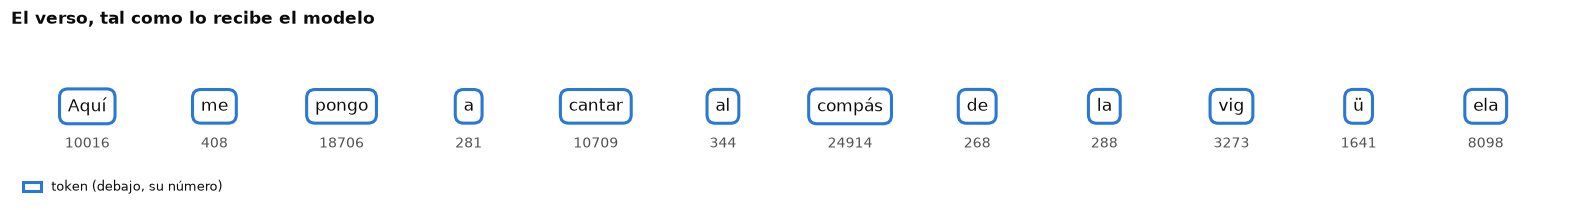

In [4]:
# Los rotulos esconden el espacio que algunos tokens llevan adelante.
rotulos = []
for token in tokens:
    rotulos.append(token.strip())

utils.dibujar_fichas(
    piezas=rotulos,
    clases=["token"] * cantidad_de_tokens,
    estilos={"token": (utils.AZUL, "token (debajo, su n\u00famero)")},
    titulo="El verso, tal como lo recibe el modelo",
    notas=numeros,
)

> **Para mirar.**
>
> - Casi todas las palabras son un token entero. *Vigüela* se parte en tres (`vig`, `ü`, `ela`): no está entera en el vocabulario, que se arma con las secuencias frecuentes de los datos de entrenamiento.
> - Varios tokens empiezan con un espacio (`" me"`): el espacio es parte del token. Los rótulos lo esconden para que se lean mejor.

Antes de entrar al detalle, el mapa del modelo. No está dibujado a mano: las medidas y la cantidad de parámetros se leen del modelo cargado. En este cuaderno trabajamos en la caja marcada.

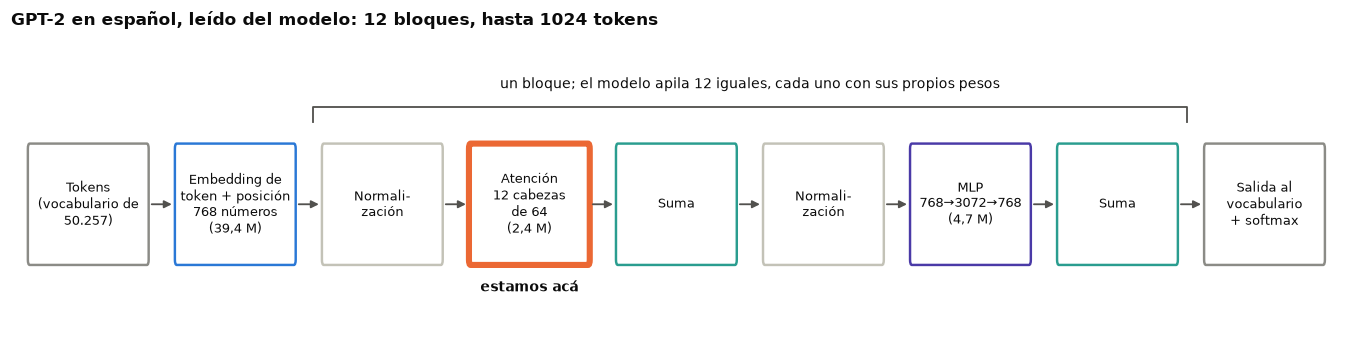

In [5]:
utils.dibujar_mapa_del_modelo(modelo, estamos_aca="atencion")

> **Para mirar.** El modelo repite el mismo tipo de bloque 12 veces, cada vez con pesos propios. La atención es una pieza de cada bloque. Abrimos la del **primer bloque** (la capa 0); al final miramos otras.

## 2. Abrir el mecanismo: una consulta y una clave

**Qué entra a la atención.** Cada token llega como un vector de 768 números: el de su token más el de su posición en el texto (cuaderno 01). Antes de la atención, el bloque **normaliza** esos vectores, una cuenta que abrimos en el cuaderno 03. Acá los tomamos tal como los calcula el modelo.

**Python nuevo:** `torch.no_grad()` avisa que no vamos a entrenar: el modelo no guarda lo necesario para corregir pesos y calcula más rápido. `.numpy()` pasa el resultado de PyTorch a NumPy.

In [6]:
posiciones = torch.arange(cantidad_de_tokens)
primer_bloque = modelo.transformer.h[0]

with torch.no_grad():
    vectores_de_token = modelo.transformer.wte(ids_del_verso)
    vectores_de_posicion = modelo.transformer.wpe(posiciones)
    entrada_del_bloque = vectores_de_token + vectores_de_posicion
    entrada_normalizada = primer_bloque.ln_1(entrada_del_bloque)

entrada_de_la_atencion = entrada_normalizada[0].numpy()
print(f"Una fila por token, 768 numeros por fila: "
      f"{entrada_de_la_atencion.shape}")

Una fila por token, 768 numeros por fila: (12, 768)


**Tres papeles para cada token.** La atención le da a cada token tres vectores nuevos:

| Papel | Qué hace |
|---|---|
| **consulta** (*query*) | lo que el token busca en los anteriores |
| **clave** (*key*) | con qué se lo compara cuando otro token busca |
| **valor** (*value*) | lo que aporta si otro token lo elige |

Los tres salen de multiplicar la entrada por pesos aprendidos, como la neurona del cuaderno 01. GPT-2 guarda los tres juegos de pesos en **una sola matriz de 768 × 2304**: las primeras 768 columnas dan la consulta, las 768 siguientes la clave y las últimas 768 el valor. Cada tramo de 768 se reparte entre **12 cabezas de 64**: la cabeza 0, la que usamos, toma las primeras 64 columnas de cada tramo.

**Python nuevo:** `@` es el producto de matrices: la cuenta de la neurona (multiplicar y sumar) hecha para todas las filas y columnas a la vez. `.detach()` separa los pesos del registro que PyTorch usa para entrenar.

In [7]:
pesos_qkv = primer_bloque.attn.c_attn.weight.detach().numpy()
sesgos_qkv = primer_bloque.attn.c_attn.bias.detach().numpy()
print(f"Pesos de consulta, clave y valor juntos: {pesos_qkv.shape}")

proyecciones = entrada_de_la_atencion @ pesos_qkv + sesgos_qkv

# Cabeza 0: las primeras 64 columnas de cada tramo de 768.
consultas = proyecciones[:, 0:64]
claves = proyecciones[:, 768:832]
valores = proyecciones[:, 1536:1600]
print(f"Consultas de la cabeza 0: {consultas.shape}")

Pesos de consulta, clave y valor juntos: (768, 2304)
Consultas de la cabeza 0: (12, 64)


Ahora, dos vectores reales: la **consulta de «cantar»** y la **clave de «pongo»**. El color dice el signo (naranja, positivo; azul, negativo) y la intensidad, el tamaño. El recuadro marca las cuatro primeras coordenadas, las que vamos a usar en la cuenta a mano.

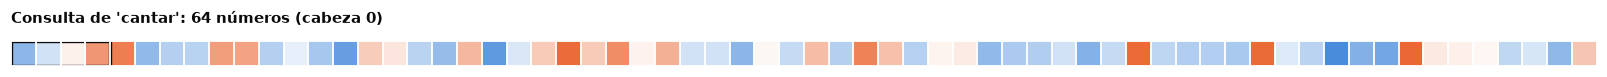

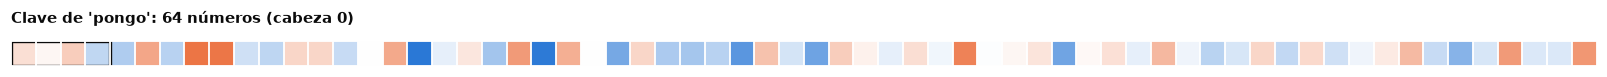

In [8]:
posicion_de_cantar = 4
posicion_de_pongo = 2
consulta_de_cantar = consultas[posicion_de_cantar]
clave_de_pongo = claves[posicion_de_pongo]

utils.dibujar_paneles(paneles=[{
    "matriz": consulta_de_cantar, "tipo": "vector", "marco": (0, 0, 1, 4),
    "titulo": "Consulta de 'cantar': 64 n\u00fameros (cabeza 0)",
}])
utils.dibujar_paneles(paneles=[{
    "matriz": clave_de_pongo, "tipo": "vector", "marco": (0, 0, 1, 4),
    "titulo": "Clave de 'pongo': 64 n\u00fameros (cabeza 0)",
}])

### Paso 1: el recorte, con números reales

Tomamos las cuatro coordenadas del recuadro y las redondeamos a dos decimales para poder hacer la cuenta a mano.

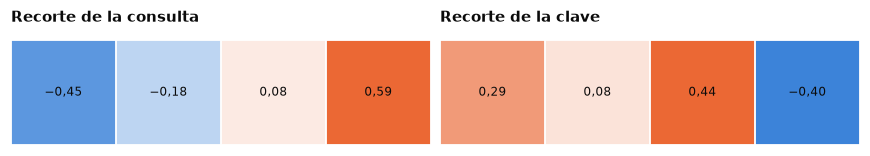

In [9]:
recorte_de_la_consulta = np.round(consulta_de_cantar[0:4], decimals=2)
recorte_de_la_clave = np.round(clave_de_pongo[0:4], decimals=2)

utils.dibujar_paneles(paneles=[
    {"matriz": recorte_de_la_consulta, "tipo": "vector", "numeros": True,
     "titulo": "Recorte de la consulta"},
    {"matriz": recorte_de_la_clave, "tipo": "vector", "numeros": True,
     "titulo": "Recorte de la clave"},
])

### Paso 2: la cuenta, escrita completa

Multiplicamos cada número de la consulta por el de la clave que está en la misma posición:

* Posición 1: −0,45 × 0,29 = −0,1305
* Posición 2: −0,18 × 0,08 = −0,0144
* Posición 3: 0,08 × 0,44 = 0,0352
* Posición 4: 0,59 × (−0,40) = −0,2360

Y sumamos: −0,1305 − 0,0144 + 0,0352 − 0,2360 = **−0,3457**.

**La misma idea en una frase:** *multiplicá cada número de la consulta por el de la clave en la misma posición y sumá todo.* Se llama **producto punto**: da un número alto cuando los dos vectores tienen números grandes del mismo signo en las mismas posiciones.

**Recién ahora, el símbolo.** Con $q$ para la consulta, $k$ para la clave y un subíndice para la posición:

$$q \cdot k = q_1 k_1 + q_2 k_2 + \dots + q_{64} k_{64}$$

El código hace la misma cuenta: primero con el recorte, después con las 64 coordenadas.

In [10]:
producto_del_recorte = 0.0
for posicion in range(4):
    producto = recorte_de_la_consulta[posicion] * recorte_de_la_clave[posicion]
    producto_del_recorte = producto_del_recorte + producto

producto_completo = 0.0
for posicion in range(64):
    producto = consulta_de_cantar[posicion] * clave_de_pongo[posicion]
    producto_completo = producto_completo + producto

producto_con_arroba = consulta_de_cantar @ clave_de_pongo
print(f"Con 4 coordenadas:  {producto_del_recorte:.4f}")
print(f"Con las 64:         {producto_completo:.4f}")
print(f"Con @ (la misma):   {producto_con_arroba:.4f}")

Con 4 coordenadas:  -0.3457
Con las 64:         1.0506
Con @ (la misma):   1.0506


> **Para mirar.** Con 4 de las 64 coordenadas la cuenta da −0,35; con las 64 da 1,05: **cambia hasta el signo**. El recorte sirve para ver cómo es la cuenta, no para sacar conclusiones. El bucle y `@` dan lo mismo: `@` es el bucle, escrito corto.

### Paso 3: dividir por 8

GPT-2 divide cada producto por la raíz cuadrada del tamaño de la cabeza: √64 = 8. Por qué lo hace lo vemos en la sección 5.

In [11]:
puntaje_de_cantar_con_pongo = producto_completo / 8
print(f"Puntaje de 'cantar' con 'pongo': {puntaje_de_cantar_con_pongo:.4f}")

Puntaje de 'cantar' con 'pongo': 0.1313


## 3. Una fila: cuánto toma «cantar» de cada token anterior

«cantar» compara su consulta con la clave de cada token que tiene antes, y también con la suya: «Aquí», «me», «pongo», «a», «cantar». Los que vienen después no cuentan: cuando el modelo escribe, todavía no existen (sección 4).

In [12]:
puntajes_de_cantar = []
for posicion in range(posicion_de_cantar + 1):
    producto = consulta_de_cantar @ claves[posicion]
    puntajes_de_cantar.append(producto / 8)

puntajes_de_cantar = np.array(puntajes_de_cantar)
print(f"Puntajes: {puntajes_de_cantar}")

Puntajes: [ 0.76 -0.33  0.13 -0.91 -0.56]


Los puntajes pueden ser negativos y no suman nada en particular. **Softmax** los convierte en pesos positivos que suman 1: a cada puntaje le aplica la exponencial ($e^{x}$, siempre positiva y más grande cuanto más grande es $x$) y divide por la suma de todas. Restar antes el máximo no cambia el resultado y evita números gigantes.

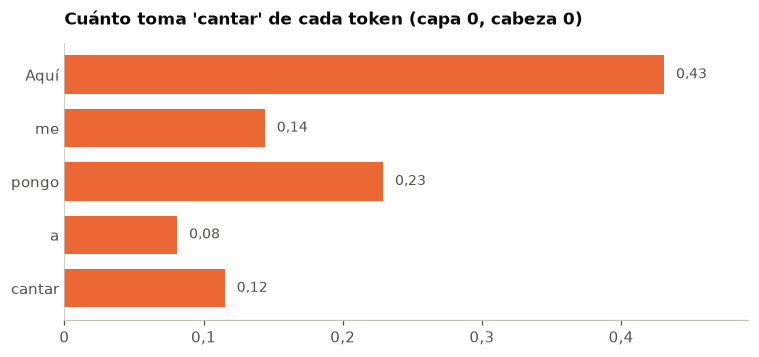

In [13]:
def softmax(puntajes: np.ndarray) -> np.ndarray:
    """Convierte puntajes en pesos positivos que suman uno.

    Args:
        puntajes: Puntajes de los tokens considerados.

    Returns:
        Pesos normalizados, en el mismo orden.
    """
    puntajes_estables = puntajes - puntajes.max()
    exponenciales = np.exp(puntajes_estables)
    return exponenciales / exponenciales.sum()


pesos_de_cantar = softmax(puntajes_de_cantar)
utils.dibujar_barras(
    nombres=rotulos[0:posicion_de_cantar + 1],
    valores=pesos_de_cantar,
    titulo="Cu\u00e1nto toma 'cantar' de cada token (capa 0, cabeza 0)",
    color=utils.NARANJA,
)

**¿Es la cuenta del modelo?** El modelo devuelve sus pesos de atención si se los pedimos (`output_attentions=True`). Vienen ordenados por capa y, dentro de cada capa, por texto, cabeza, fila y columna.

In [14]:
with torch.no_grad():
    salida_del_modelo = modelo(ids_del_verso, output_attentions=True)

# Una matriz por capa; dentro, una por cabeza. El [0] es el unico texto.
atencion_del_verso = []
for capa_del_modelo in salida_del_modelo.attentions:
    atencion_del_verso.append(capa_del_modelo[0].numpy())

cabezas_de_la_capa_0 = atencion_del_verso[0]
print(f"Capa 0: {cabezas_de_la_capa_0.shape} (cabezas, filas, columnas)")

fila_del_modelo = cabezas_de_la_capa_0[0, posicion_de_cantar, 0:5]
diferencia = np.abs(pesos_de_cantar - fila_del_modelo).max()
print(f"Nuestra cuenta: {pesos_de_cantar}")
print(f"La del modelo:  {fila_del_modelo}")
print(f"Mayor diferencia: {diferencia:.1e}")

Capa 0: (12, 12, 12) (cabezas, filas, columnas)
Nuestra cuenta: [0.43 0.14 0.23 0.08 0.12]
La del modelo:  [0.43 0.14 0.23 0.08 0.12]
Mayor diferencia: 6.0e-08


> **Para mirar.**
>
> - Las dos filas coinciden: la diferencia es menor que una diezmillonésima, lo que se pierde al redondear decimales. **Es la cuenta del modelo.**
> - Lo que más pesa es «Aquí» (0,43), después «pongo» (0,23). No lo leas todavía como «cantar se fija en el comienzo del verso»: la sección 6 muestra por qué.

**Lo que se lleva «cantar».** Con esos pesos, «cantar» arma un vector nuevo: suma los **valores** de los cinco tokens, cada uno multiplicado por su peso.

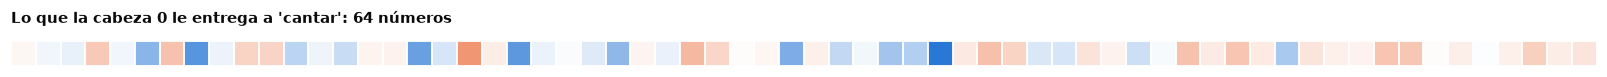

In [15]:
vector_de_contexto = np.zeros(64)
for posicion in range(posicion_de_cantar + 1):
    aporte = pesos_de_cantar[posicion] * valores[posicion]
    vector_de_contexto = vector_de_contexto + aporte

utils.dibujar_paneles(paneles=[{
    "matriz": vector_de_contexto, "tipo": "vector",
    "titulo": "Lo que la cabeza 0 le entrega a 'cantar': 64 n\u00fameros",
}])

> **Para mirar.** Es una mezcla de los valores de los cinco tokens, en la proporción de las barras de arriba. Las 12 cabezas hacen lo mismo con sus propios pesos y el bloque junta los 12 resultados: eso es el cuaderno 03.

## 4. La matriz completa y el futuro tapado

Lo mismo para los 12 tokens da 12 filas. Con `@` y las claves **traspuestas** (`.T`, filas por columnas) salen todos los productos de una vez: la fila 4 de la matriz es la fila de «cantar» de la sección 3.

In [16]:
puntajes_de_la_cabeza = consultas @ claves.T / 8

fila_de_cantar = puntajes_de_la_cabeza[posicion_de_cantar, 0:5]
es_la_misma = np.allclose(fila_de_cantar, puntajes_de_cantar)
print(f"Forma: {puntajes_de_la_cabeza.shape}")
print(f"Coincide con la fila de la seccion 3: {es_la_misma}")

Forma: (12, 12)
Coincide con la fila de la seccion 3: True


Pero la matriz tiene puntajes **hacia el futuro**: la fila de «cantar» también tiene columnas para «compás» o «vigüela». GPT-2 escribe de a un token y no puede usar lo que todavía no escribió. La **máscara causal** tapa esas celdas: pone su puntaje en menos infinito, y como $e^{-\infty} = 0$, softmax les da peso cero.

Una celda está en el futuro cuando su columna es mayor que su fila.

In [17]:
tapado = np.zeros((cantidad_de_tokens, cantidad_de_tokens), dtype=bool)
for fila in range(cantidad_de_tokens):
    for columna in range(cantidad_de_tokens):
        if columna > fila:
            tapado[fila, columna] = True

puntajes_con_mascara = puntajes_de_la_cabeza.copy()
puntajes_con_mascara[tapado] = -np.inf

# utils.softmax es la de la seccion 3, aplicada a todas las filas juntas.
matriz_de_atencion = utils.softmax(puntajes_con_mascara)

diferencia = np.abs(matriz_de_atencion - cabezas_de_la_capa_0[0]).max()
print(f"Mayor diferencia con la matriz del modelo: {diferencia:.1e}")

Mayor diferencia con la matriz del modelo: 8.9e-08


La escena muestra la matriz. Arriba, la versión estática con todas las filas. Abajo, si tu entorno muestra controles, mové **Fila** para verla llenarse de a un token, como la calcula el modelo cuando escribe.

Escena inicial (estática):


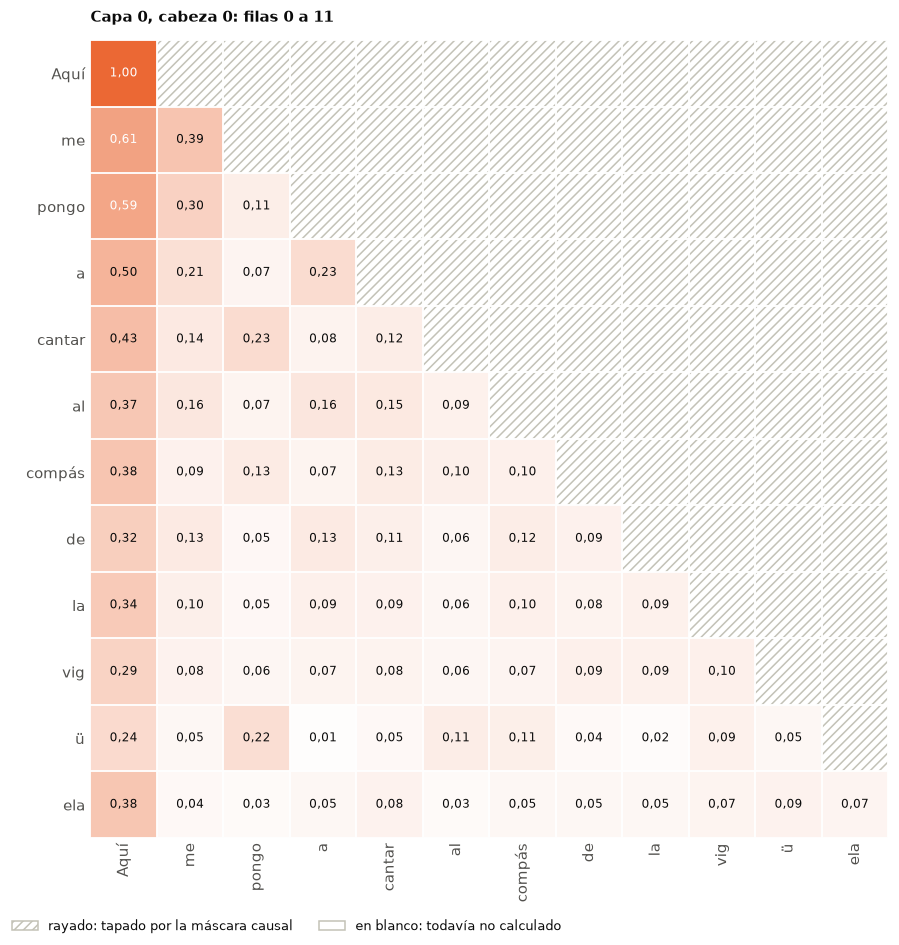

In [18]:
def escena_de_la_matriz(hasta_la_fila: int) -> None:
    """Dibuja la matriz de atencion calculada hasta una fila.

    Args:
        hasta_la_fila: Ultima fila que se muestra calculada.
    """
    matriz_parcial = matriz_de_atencion.copy()
    matriz_parcial[hasta_la_fila + 1:] = np.nan
    utils.dibujar_paneles(paneles=[{
        "matriz": matriz_parcial, "tipo": "atencion", "numeros": True,
        "mascara": tapado, "filas": rotulos, "columnas": rotulos,
        "titulo": f"Capa 0, cabeza 0: filas 0 a {hasta_la_fila}",
    }])


controles_de_la_matriz = {
    "hasta_la_fila": widgets.IntSlider(
        value=cantidad_de_tokens - 1, min=0, max=cantidad_de_tokens - 1,
        description="Fila:", continuous_update=False,
    ),
}
utils.armar_panel_interactivo(
    funcion_de_escena=escena_de_la_matriz,
    controles=controles_de_la_matriz,
)

> **Para mirar.**
>
> - La matriz es un triángulo: arriba de la diagonal, todo rayado. Cada token usa solo lo anterior y a sí mismo.
> - La primera fila tiene un 1,00: «Aquí» no tiene a nadie antes, así que toma todo de sí mismo.
> - Cada fila suma 1. Y la diferencia con la matriz del modelo es, otra vez, de redondeo.

### Microlaboratorio 1 — La fila de «compás»

**Tarea.** Recalcular cuánto toma «compás» de cada token anterior.
**Producto.** `pesos_de_compas`, comprobado contra el modelo.
**Antes de empezar.** Secciones 2 a 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `consulta_de_compas` | la consulta de «compás» | `consultas` en la fila `posicion_de_compas` |
| (2) `claves_visibles` | las claves desde «Aquí» hasta «compás», incluida | `claves` con las filas `0:posicion_de_compas + 1` |
| (3) `puntajes_de_compas` | los productos punto, divididos por 8 | `claves_visibles @ consulta_de_compas`, todo dividido por `8` |
| (4) `pesos_de_compas` | los pesos | la función `softmax` de la sección 3 |

**Comprobación.** La fila de «compás» en la matriz que devolvió el modelo.

> **Ayuda 1.** Es la sección 3 con otra palabra.
> **Ayuda 2.** En la sección 3 el bucle hacía un producto por vez; con `@` salen todos juntos, como en la sección 4.

In [19]:
posicion_de_compas = 6

consulta_de_compas = np.zeros(64)  # COMPLETAR (1)
claves_visibles = np.zeros((7, 64))  # COMPLETAR (2)
puntajes_de_compas = np.zeros(7)  # COMPLETAR (3)
pesos_de_compas = np.zeros(7)  # COMPLETAR (4)

print(f"Tus pesos: {pesos_de_compas}")

Tus pesos: [0. 0. 0. 0. 0. 0. 0.]


In [20]:
fila_esperada = cabezas_de_la_capa_0[0, posicion_de_compas, 0:7]
utils.comprobar(
    np.allclose(pesos_de_compas, fila_esperada, atol=1e-5),
    "revisa (1) a (4): la fila no coincide con la del modelo.",
)

Todavia no. revisa (1) a (4): la fila no coincide con la del modelo.


## 5. Por qué dividir por 8

**Experimento, con un error deliberado.** Hacemos la fila de «cantar» **sin** dividir por 8. Es un cambio hecho a propósito: con esta cuenta ya no estamos calculando lo que calcula GPT-2.

Productos sin dividir: de -7.26 a 6.11


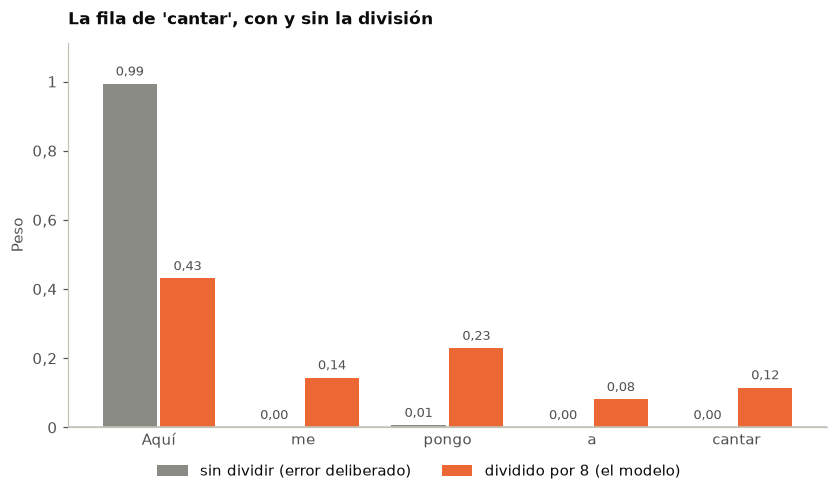

In [21]:
productos_de_cantar = claves[0:5] @ consulta_de_cantar

# --- Error deliberado: se omite la division por 8. ---
pesos_sin_dividir = softmax(productos_de_cantar)
# --- Fin del error deliberado. ---

minimo = productos_de_cantar.min()
maximo = productos_de_cantar.max()
print(f"Productos sin dividir: de {minimo:.2f} a {maximo:.2f}")
utils.dibujar_barras_agrupadas(
    categorias=rotulos[0:5],
    series={
        "sin dividir (error deliberado)": pesos_sin_dividir,
        "dividido por 8 (el modelo)": pesos_de_cantar,
    },
    titulo="La fila de 'cantar', con y sin la divisi\u00f3n",
    etiqueta_y="Peso",
)

> **Para mirar.** Sin dividir, «Aquí» se lleva 0,99 y los demás tokens casi nada. Una suma de 64 productos puede dar números grandes (acá van de −7,26 a 6,11), y softmax con números grandes le da casi todo al mayor. Dividir por √64 = 8 los achica y la mezcla se mantiene repartida. Un reparto tan extremo también entorpece el entrenamiento: casi no queda señal para corregir los demás pesos.

Probá otros divisores. El modelo se entrenó con 8: cualquier otro número es otra cuenta.

Escena inicial (estática):


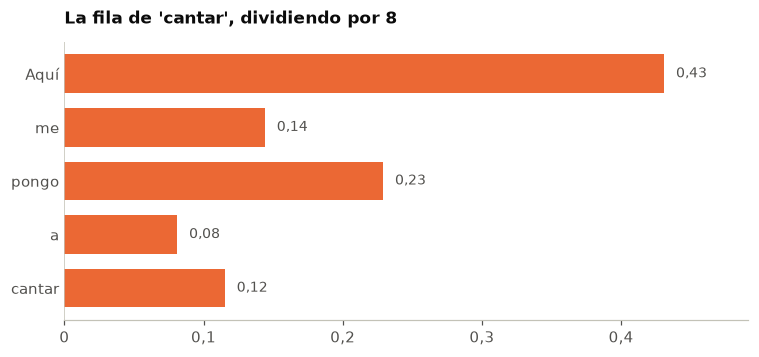

In [22]:
def escena_del_divisor(divisor: int) -> None:
    """Dibuja la fila de cantar con otro divisor.

    Args:
        divisor: Numero por el que se dividen los productos.
    """
    pesos = softmax(productos_de_cantar / divisor)
    utils.dibujar_barras(
        nombres=rotulos[0:5],
        valores=pesos,
        titulo=f"La fila de 'cantar', dividiendo por {divisor}",
        color=utils.NARANJA,
    )


controles_del_divisor = {
    "divisor": widgets.Dropdown(
        options=[1, 2, 4, 8, 16], value=8, description="Divisor:",
    ),
}
utils.armar_panel_interactivo(
    funcion_de_escena=escena_del_divisor,
    controles=controles_del_divisor,
)

## 6. Donde la lectura se vuelve insuficiente: 144 maneras de mirar

El modelo calcula una matriz como esta por cabeza y por capa: 12 × 12 = **144** para el mismo verso. Desde la capa 1, la entrada de la atención ya pasó por los bloques anteriores. No la recalculamos: tomamos las matrices que devuelve el modelo. En la capa 0 ya comprobamos que la cuenta es la misma.

Tres cabezas, elegidas porque miran de maneras muy distintas:

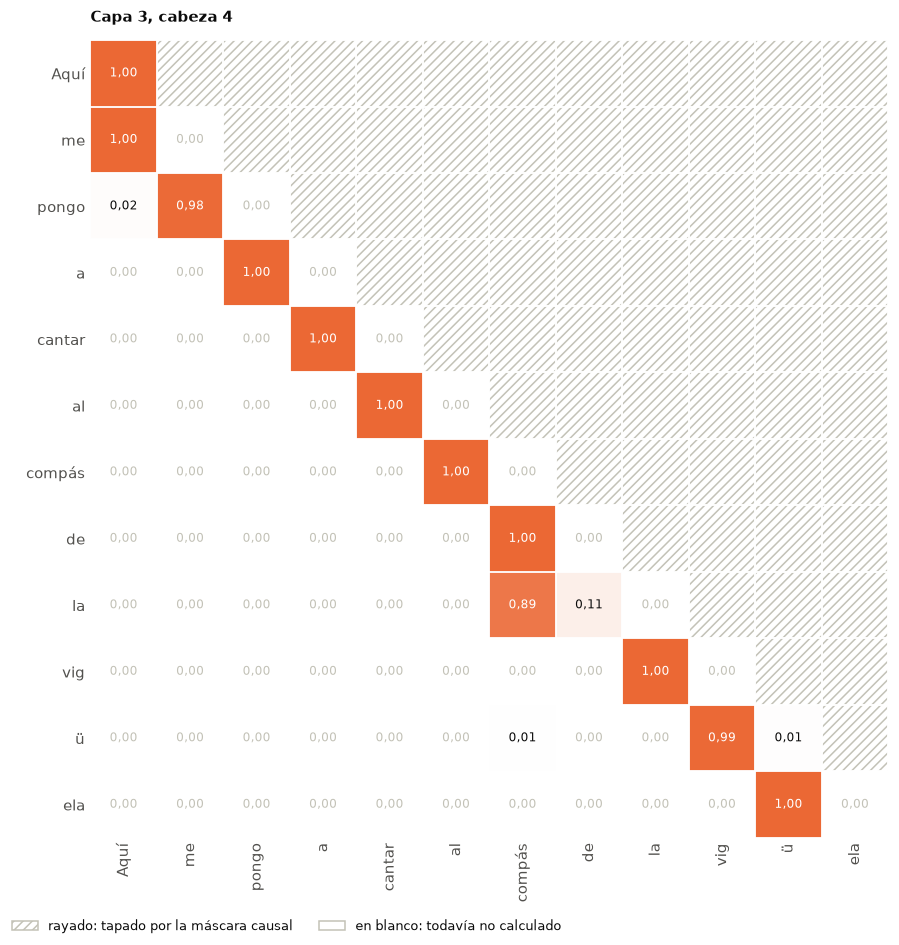

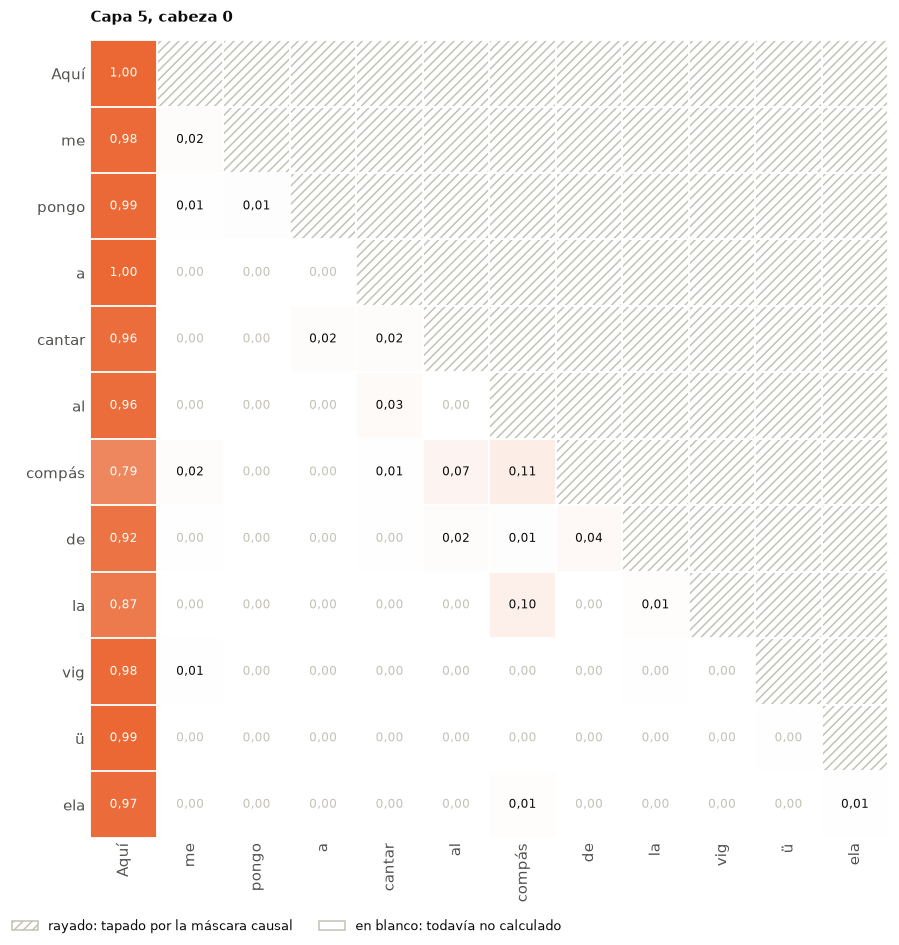

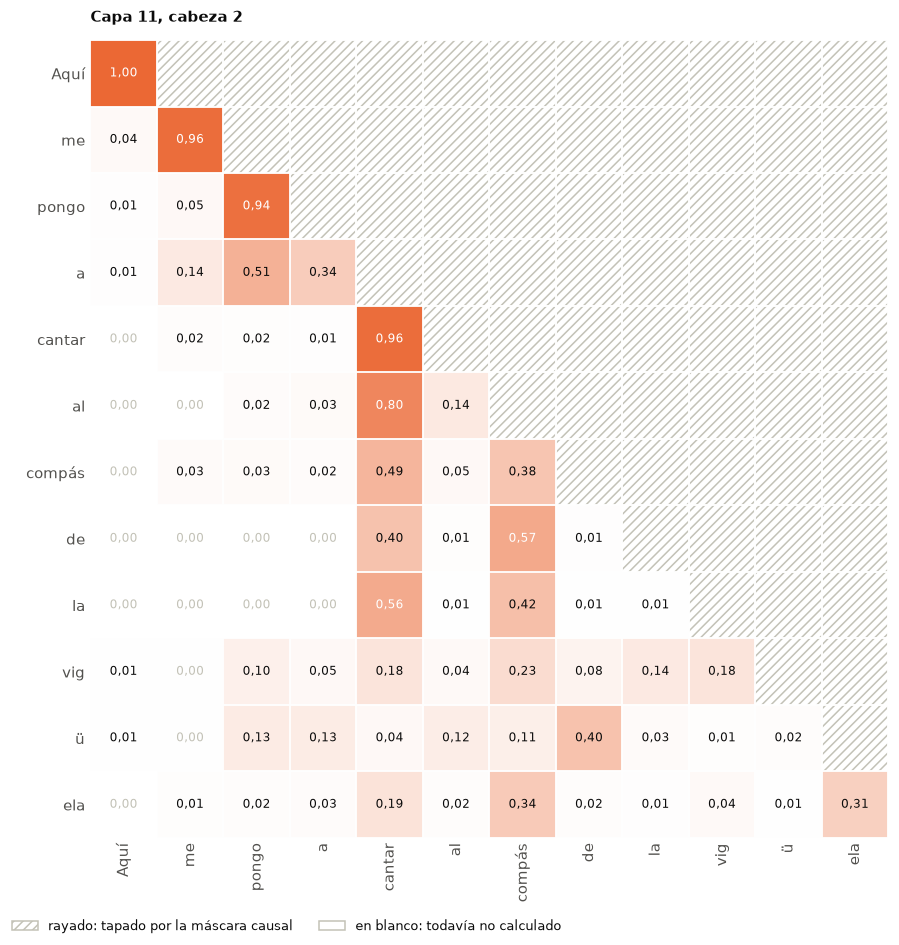

In [23]:
cabezas_elegidas = [
    {"capa": 3, "cabeza": 4},
    {"capa": 5, "cabeza": 0},
    {"capa": 11, "cabeza": 2},
]

for elegida in cabezas_elegidas:
    capa = elegida["capa"]
    cabeza = elegida["cabeza"]
    utils.dibujar_paneles(paneles=[{
        "matriz": atencion_del_verso[capa][cabeza], "tipo": "atencion",
        "numeros": True, "mascara": tapado, "filas": rotulos,
        "columnas": rotulos, "titulo": f"Capa {capa}, cabeza {cabeza}",
    }])

> **Para mirar.**
>
> - **Capa 3, cabeza 4:** casi todo va al token **anterior** (la diagonal de abajo).
> - **Capa 5, cabeza 0:** casi todo va al **primer** token, desde cualquier fila.
> - **Capa 11, cabeza 2:** desde «al», «compás», «de» y «la», buena parte del peso va a «cantar» y a «compás». Es tentador leerlo como «el modelo entiende que el compás es del canto». **No alcanza:** es una cabeza entre 144, sobre un solo verso.

**¿Por qué tanto peso al primer token?** Ya pasó en la capa 0: «Aquí» recibía 0,43 de «cantar». Probemos cambiar «Aquí» por «Ya» y medir el peso promedio que recibe el primer token en las 12 cabezas de la capa 0.

In [24]:
def peso_promedio_al_primer_token(texto: str) -> float:
    """Mide cuanto peso recibe el primer token en la capa 0.

    Args:
        texto: Texto que se le da al modelo.

    Returns:
        Promedio, sobre las 12 cabezas y desde el segundo token, del peso
        que va al primer token.
    """
    ids = tokenizador(texto, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        salida = modelo(ids, output_attentions=True)
    capa_0 = salida.attentions[0]
    cabezas = capa_0[0].numpy()
    # Todas las cabezas, desde la fila 1, columna 0.
    return float(cabezas[:, 1:, 0].mean())


verso_con_otro_comienzo = "Ya me pongo a cantar al compás de la vigüela"
con_aqui = peso_promedio_al_primer_token(verso)
con_ya = peso_promedio_al_primer_token(verso_con_otro_comienzo)
print(f"Primer token 'Aqu\u00ed': {con_aqui:.2f}")
print(f"Primer token 'Ya':   {con_ya:.2f}")

Primer token 'Aquí': 0.45
Primer token 'Ya':   0.44


> **Para mirar.** 0,45 con «Aquí» y 0,44 con «Ya»: el peso **no depende de la palabra**. Una explicación frecuente en la literatura es que el modelo usa el primer token como un lugar donde «dejar» la atención que no necesita (se lo suele llamar *sumidero de atención*). Acá no lo probamos; solo comprobamos que no tiene que ver con «Aquí». **Un peso alto no es una explicación.**

Mirá cualquiera de las 144 cabezas:

Escena inicial (estática):


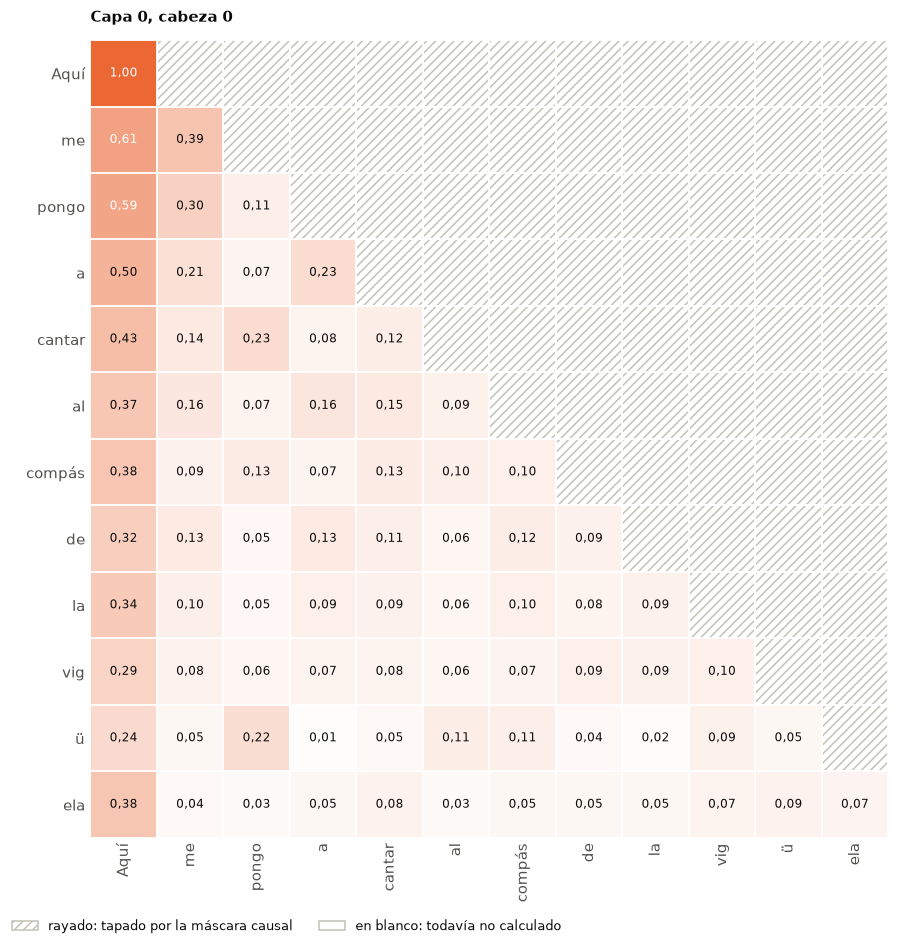

In [25]:
def escena_de_una_cabeza(capa: int, cabeza: int) -> None:
    """Dibuja la matriz de atencion de una cabeza.

    Args:
        capa: Capa, de 0 a 11.
        cabeza: Cabeza, de 0 a 11.
    """
    utils.dibujar_paneles(paneles=[{
        "matriz": atencion_del_verso[capa][cabeza], "tipo": "atencion",
        "numeros": True, "mascara": tapado, "filas": rotulos,
        "columnas": rotulos, "titulo": f"Capa {capa}, cabeza {cabeza}",
    }])


controles_de_la_cabeza = {
    "capa": widgets.Dropdown(options=list(range(12)), value=0,
                             description="Capa:"),
    "cabeza": widgets.Dropdown(options=list(range(12)), value=0,
                               description="Cabeza:"),
}
utils.armar_panel_interactivo(
    funcion_de_escena=escena_de_una_cabeza,
    controles=controles_de_la_cabeza,
)

### Microlaboratorio 2 — Medir cuánto mira al token anterior

**Tarea.** Convertir «esta cabeza mira al anterior» en un número: el peso promedio que cada token le da al token que tiene justo antes.
**Producto.** La función `peso_al_anterior`, comprobada, y tu decisión.
**Antes de empezar.** Sección 6.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `peso` | el peso que la fila le da al token anterior | `matriz` en la fila `fila` y la columna `fila - 1` |
| (2) `suma` | la suma acumulada | `suma + peso` |
| (3) `promedio` | el promedio | `suma` dividido por `cantidad` |

**Comprobación.** Otra forma de calcularlo: `np.diagonal` toma la diagonal de abajo de la matriz.

> **Ayuda 1.** El token anterior al de la fila 5 está en la columna 4.
> **Ayuda 2.** Es el mismo patrón de acumulación que el producto punto de la sección 2.

In [26]:
def peso_al_anterior(matriz: np.ndarray) -> float:
    """Mide cuanto peso da cada token, en promedio, al token anterior.

    Args:
        matriz: Matriz de atencion de una cabeza.

    Returns:
        Promedio del peso al token anterior, desde la segunda fila.
    """
    suma = 0.0
    cantidad = 0
    for fila in range(1, len(matriz)):
        peso = 0.0  # COMPLETAR (1)
        suma = suma  # COMPLETAR (2)
        cantidad = cantidad + 1
    promedio = 0.0  # COMPLETAR (3)
    return promedio


matriz_capa_3_cabeza_4 = atencion_del_verso[3][4]
medida = peso_al_anterior(matriz_capa_3_cabeza_4)
print(f"Capa 3, cabeza 4: {medida:.2f}")

Capa 3, cabeza 4: 0.00


In [27]:
referencia = np.diagonal(matriz_capa_3_cabeza_4, offset=-1).mean()
utils.comprobar(
    np.isclose(medida, referencia),
    "revisa (1) a (3): la medida no coincide con la diagonal de abajo.",
)

Todavia no. revisa (1) a (3): la medida no coincide con la diagonal de abajo.


**PASO 2.** Medí las otras cabezas de la sección 6 y la cabeza 0 de la capa 0. Podés sumar las que encuentres con el selector.

In [28]:
cabezas_a_medir = [
    {"capa": 0, "cabeza": 0},
    {"capa": 3, "cabeza": 4},
    {"capa": 5, "cabeza": 0},
    {"capa": 11, "cabeza": 2},
]

for elegida in cabezas_a_medir:
    capa = elegida["capa"]
    cabeza = elegida["cabeza"]
    matriz = atencion_del_verso[capa][cabeza]
    medida_de_la_cabeza = peso_al_anterior(matriz)
    print(f"Capa {capa:2d}, cabeza {cabeza:2d}: {medida_de_la_cabeza:.2f}")

Capa  0, cabeza  0: 0.00
Capa  3, cabeza  4: 0.00
Capa  5, cabeza  0: 0.00
Capa 11, cabeza  2: 0.00


**PASO 3.** Una cabeza con una medida alta, ¿alcanza para decir que el modelo «entiende» el orden de las palabras? Escribí tu decisión en `mi_decision` y apoyala en un número de este cuaderno.

In [29]:
mi_decision = ""
print(mi_decision)

## Qué te llevás

- La atención compara la **consulta** de un token con las **claves** de los anteriores (producto punto dividido por 8), convierte esos puntajes en pesos con **softmax** y suma los **valores** con esos pesos.
- La **máscara causal** tapa el futuro: por eso GPT-2 puede escribir de a un token. La cuenta de este cuaderno es la del modelo: coinciden salvo por el redondeo.
- Cada una de las 144 cabezas mira distinto, y **un peso alto no es una explicación**: el primer token recibe casi la mitad del peso aunque cambie la palabra.

**Sigue:** en el cuaderno 03, cómo se juntan las 12 cabezas y cómo el bloque llega a puntuar el próximo token; en el 04, la atención de BETO, un modelo que sí mira hacia los dos lados.